# 05 · Machine learning (1/3): predicting the crowd index - **regression**

In notebooks 03-04 the crowd index was *measured* from tickets. Now the question flips:

> **Can a model *predict* the crowd index of a stretch from simple facts we know without tickets?**
> (hour of day, weekday or weekend, position on the route, distance to the city centre, how many buses run, AC or not ...)

**Why that matters for the project:** for a new route, or a stretch with almost no tickets, a model can give a sensible estimate. It also shows *what drives* crowding.

**Regression** = predicting a **number** (here: ticketed riders per bus). You will meet these models, from simple to powerful:
`Linear Regression -> Ridge / Lasso -> Polynomial -> KNN -> SVM (SVR) -> Decision Tree -> Random Forest -> Gradient Boosting`

**How we score them** (on data the model has *not* seen):
- **MAE** - average size of the error (in index units; lower is better)
- **RMSE** - like MAE but punishes big mistakes more
- **R²** - share of the variation explained: 1 = perfect, 0 = no better than always guessing the average, negative = worse than that

In [1]:
# --- Setup: run this cell first ---------------------------------------------------------------
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))        # lets the notebook find config.py and the src/ folder
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from src import db

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30, "display.width", 140)

print("Data mode:", config.MODE.upper(), "| database:", config.DB_NAME if config.USE_MYSQL else "SQLite file")

import time, joblib
from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from src import ml_features as mf

Data mode: REAL | database: SQLite file


## 1. Build the dataset
**One row = one stretch of one route at one hour on weekdays (or weekends).** The target is the crowd index. The features are listed below.

| Feature | Meaning |
|---|---|
| `hour`, `is_weekend`, `is_am_peak`, `is_pm_peak` | when |
| `is_up` | route direction label (UP / DOWN) |
| `pos`, `n_stops`, `pos_frac` | where along the route (stretch number, route length in stops, 0 = start ... 1 = end) |
| `dist_from_centre_km`, `towards_centre` | distance of the stretch from Connaught Place, and whether the bus is heading *into* the city |
| `lat`, `lon` | location |
| `route_len_km` | length of the route |
| `buses_per_hour` | scheduled buses (frequency) |
| `is_ac` | AC route |

Making new columns from old ones (like `towards_centre` or `pos_frac`) is called **feature engineering**.

In [2]:
engine = db.get_engine()
cells = db.read_table("crowd_hourly_cells", engine)
patterns = db.read_table("route_patterns", engine)
attrs = db.read_table("route_attrs", engine)

ds = mf.build_ml_dataset(cells, patterns, attrs)       # only cells with at least 5 tickets, to keep the target reasonably clean
print(f"{len(ds):,} rows from {ds.route_n.nunique():,} routes | features: {len(mf.FEATURES)}")
ds[["route", "hour", "pos", "pos_frac", "dist_from_centre_km", "towards_centre", "buses_per_hour", "n_tix", "idx"]].head()

747,675 rows from 1,605 routes | features: 15


,route,hour,pos,pos_frac,dist_from_centre_km,towards_centre,buses_per_hour,n_tix,idx
0,100ADOWN,7,16,0.347826,7.513187,1,1,6.0,0.3
1,100ADOWN,7,17,0.369565,6.866583,1,1,6.0,0.3
2,100ADOWN,7,18,0.391304,6.733606,1,1,6.0,0.3
3,100ADOWN,7,19,0.413043,6.471200,1,1,6.0,0.3
4,100ADOWN,7,20,0.434783,6.382475,1,1,6.0,0.3


## 2. Look at the data first

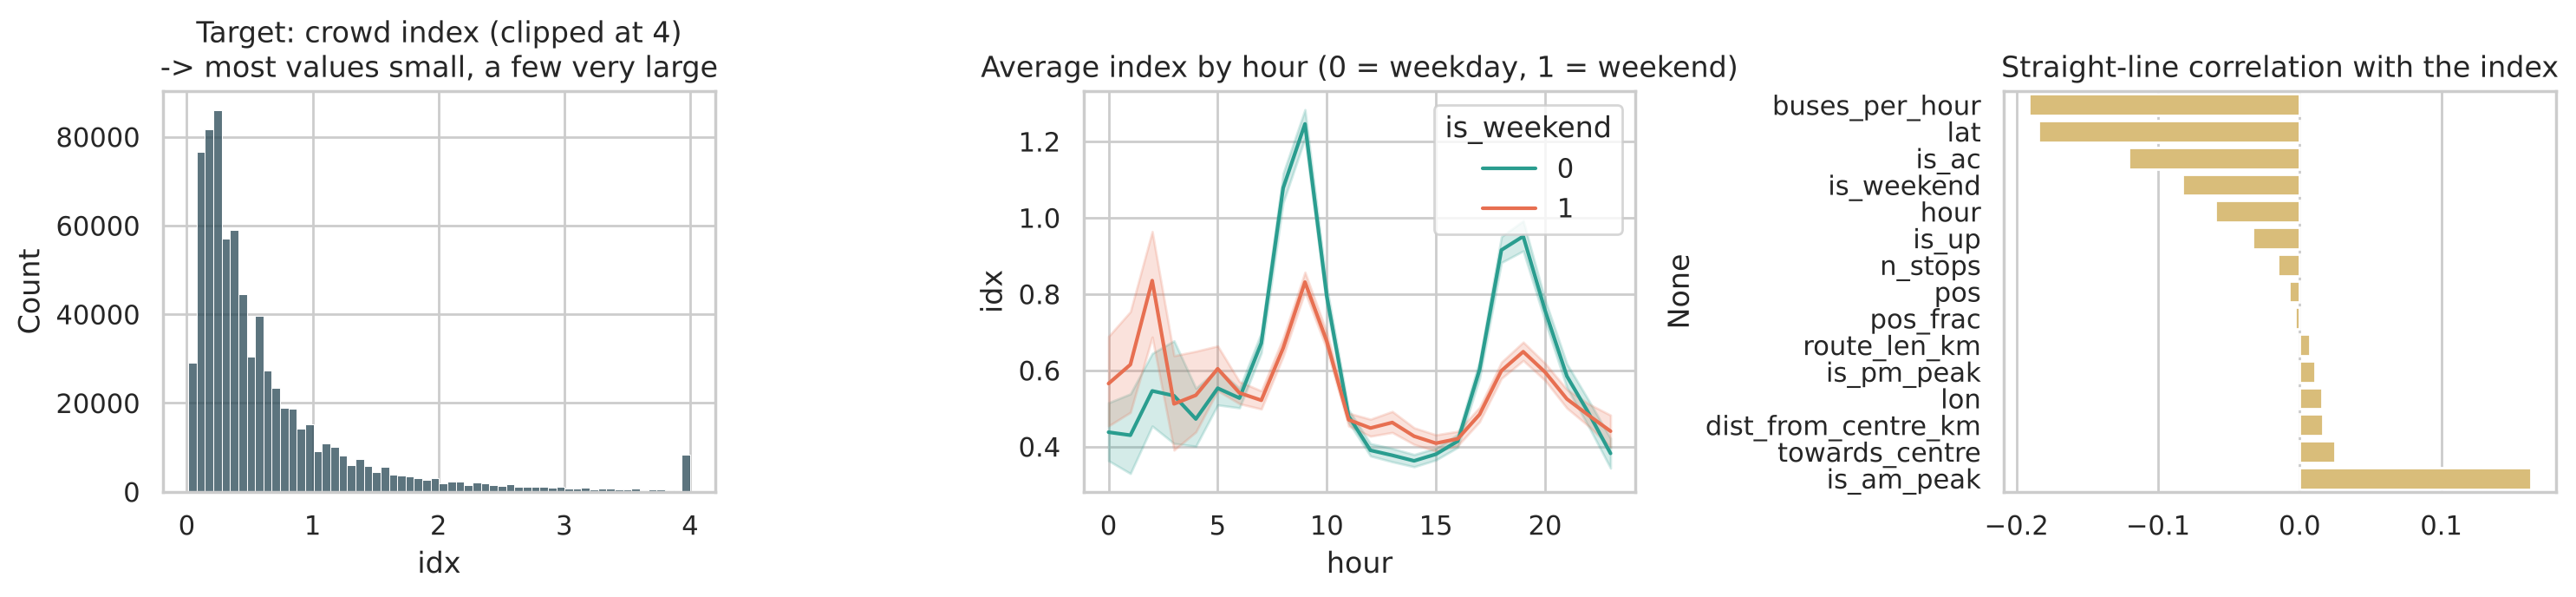

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(ds.idx.clip(upper=4), bins=60, ax=ax[0], color="#264653"); ax[0].set_title("Target: crowd index (clipped at 4)\n-> most values small, a few very large")
sns.lineplot(data=ds.sample(100000, random_state=1), x="hour", y="idx", hue="is_weekend", ax=ax[1], palette=["#2a9d8f", "#e76f51"]); ax[1].set_title("Average index by hour (0 = weekday, 1 = weekend)")
corr = ds[mf.FEATURES + ["idx"]].corr()["idx"].drop("idx").sort_values()
sns.barplot(x=corr.values, y=corr.index, ax=ax[2], color="#e9c46a"); ax[2].set_title("Straight-line correlation with the index")
plt.tight_layout(); plt.savefig(config.FIG / "05_eda.png", dpi=130); plt.show()

- The target is **skewed**: many small values, few large ones.
- The hour curve has **peaks** (morning and evening). A straight line cannot follow a curve with two humps - remember this when we meet Linear Regression.
- Correlation only measures *straight-line* relationships, so it can miss important features.

## 3. Train / test split - the most important habit in ML
We hide part of the data (the **test set**) while the model learns, then check it on that hidden part. Otherwise we would just be testing its memory.

There are **two ways to hide data**, and the difference is a good lesson:
- **Random split:** hide random rows. Easy, but neighbouring stretches of the *same route* are very alike, so the model may have "seen" the route already.
- **Unseen-routes split:** hide **whole routes**. Much harder - and exactly the real use case: *predict a route we have no tickets for.*

We also use a **20,000-row sample** (`config.ML_SAMPLE_ROWS`) because KNN and SVM become very slow on hundreds of thousands of rows.

In [4]:
S = ds.sample(config.ML_SAMPLE_ROWS, random_state=config.RANDOM_STATE).reset_index(drop=True)
X, y, groups = S[mf.FEATURES], S["idx"], S["route_n"]

tr_r, te_r = train_test_split(S.index, test_size=0.2, random_state=config.RANDOM_STATE)                       # random split
tr_g, te_g = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.RANDOM_STATE).split(S, groups=groups))   # whole routes held out
splits = {"random": (tr_r, te_r), "unseen routes": (tr_g, te_g)}
print({k: (len(a), len(b)) for k, (a, b) in splits.items()})
print("Routes shared between train and test: random split =", len(set(groups[tr_r]) & set(groups[te_r])), "| unseen-routes split =", len(set(groups[tr_g]) & set(groups[te_g])))

{'random': (16000, 4000), 'unseen routes': (15656, 4344)}
Routes shared between train and test: random split = 1001 | unseen-routes split = 0


In [5]:
results, fitted = [], {}

def run(name, make_model):
    """Train a fresh model on each split, score it on the hidden part, and remember the numbers."""
    for split, (tr, te) in splits.items():
        model = make_model()
        t0 = time.time(); model.fit(X.loc[tr], y.loc[tr]); secs = time.time() - t0
        p_tr, p_te = model.predict(X.loc[tr]), model.predict(X.loc[te])
        results.append(dict(model=name, split=split, train_R2=r2_score(y.loc[tr], p_tr), test_R2=r2_score(y.loc[te], p_te),
                            test_MAE=mean_absolute_error(y.loc[te], p_te), test_RMSE=mean_squared_error(y.loc[te], p_te) ** 0.5, fit_seconds=secs))
        if split == "random": fitted[name] = model
    return fitted[name]

run("Baseline (always the average)", lambda: DummyRegressor())
pd.DataFrame(results).round(3)

,model,split,train_R2,test_R2,test_MAE,test_RMSE,fit_seconds
0,Baseline (always the average),random,0.0,-0.001,0.504,0.874,0.003
1,Baseline (always the average),unseen routes,0.0,-0.008,0.465,0.712,0.002


## 4. The models

### 4.1 Linear Regression - draw the best straight line
Predicts `index = b0 + b1·hour + b2·pos + ...`. Fast and easy to explain; every feature gets a weight. We **scale** features first (`StandardScaler`: mean 0, spread 1) so the weights are comparable.
*Real-life example: predicting a house price from its size, bedrooms and age.*

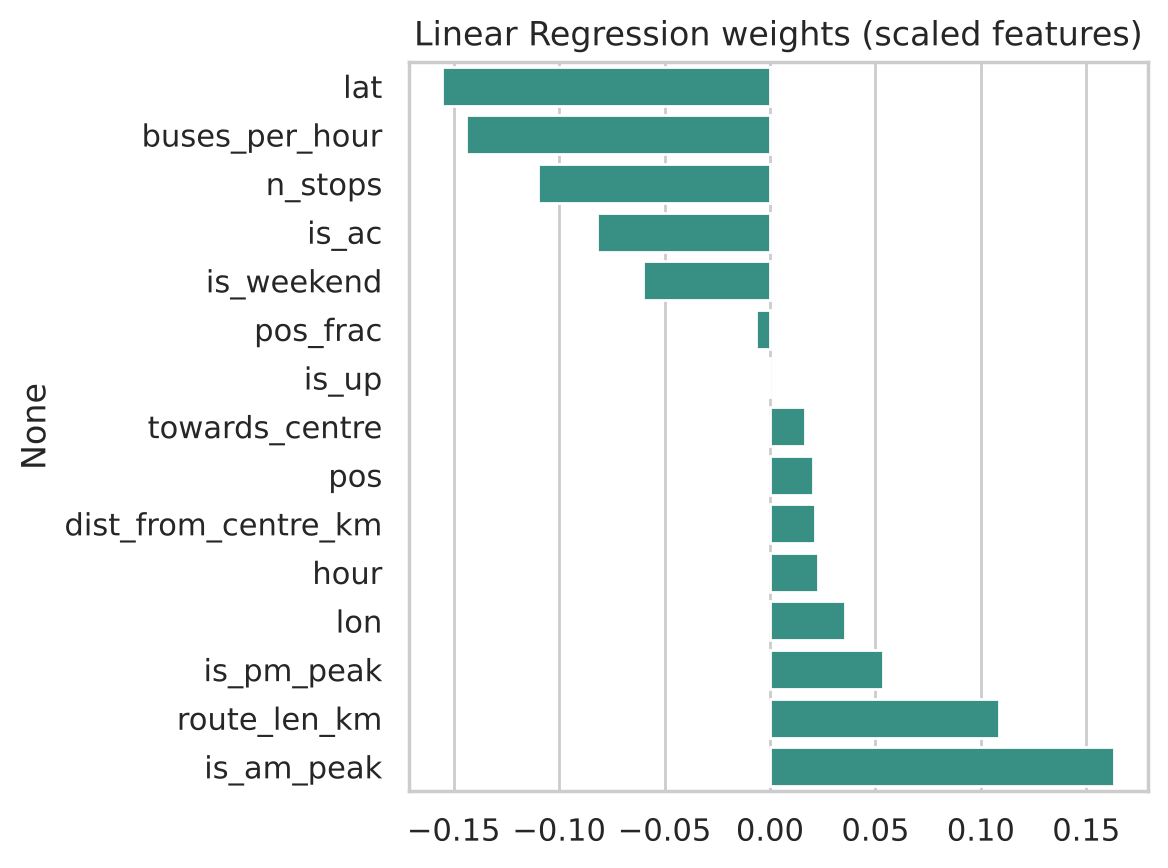

,model,split,train_R2,test_R2,test_MAE,test_RMSE,fit_seconds
2,Linear Regression,random,0.126,0.115,0.471,0.822,0.010
3,Linear Regression,unseen routes,0.128,0.093,0.421,0.675,0.008


In [6]:
lin = run("Linear Regression", lambda: make_pipeline(StandardScaler(), LinearRegression()))
w = pd.Series(lin[-1].coef_, index=mf.FEATURES).sort_values()
plt.figure(figsize=(6, 4.5)); sns.barplot(x=w.values, y=w.index, color="#2a9d8f"); plt.title("Linear Regression weights (scaled features)"); plt.tight_layout(); plt.show()
pd.DataFrame(results).round(3).tail(2)

### 4.2 Ridge and Lasso - linear regression with a brake
When features overlap (e.g. `lat`, `lon` and `dist_from_centre_km` tell similar stories), plain weights can become wild. **Ridge** shrinks all weights a little; **Lasso** can shrink some to exactly **zero**, i.e. it *selects* features.
This is called **regularisation**. *Real-life example: a teacher who stops you from over-explaining a result with too many reasons.*

In [7]:
ridge = run("Ridge", lambda: make_pipeline(StandardScaler(), Ridge(alpha=10)))
lasso = run("Lasso", lambda: make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=10000)))
wl = pd.DataFrame({"Linear": lin[-1].coef_, "Ridge": ridge[-1].coef_, "Lasso": lasso[-1].coef_}, index=mf.FEATURES)
print("Features Lasso set to exactly zero:", list(wl.index[wl.Lasso == 0]))
wl.round(3)

Features Lasso set to exactly zero: ['hour', 'is_up', 'pos', 'n_stops', 'pos_frac']


,Linear,Ridge,Lasso
hour,0.023,0.023,0.000
is_weekend,-0.060,-0.060,-0.051
is_am_peak,0.163,0.163,0.137
is_pm_peak,0.054,0.054,0.046
is_up,-0.001,-0.001,-0.000
pos,0.020,0.020,0.000
n_stops,-0.110,-0.108,-0.000
pos_frac,-0.007,-0.006,0.000
is_ac,-0.082,-0.082,-0.074
buses_per_hour,-0.144,-0.144,-0.136


### 4.3 Polynomial Regression - a straight line that can bend
Adds squares and products of features (`hour²`, `hour × pos`, ...) so the *linear* model can follow curves, like the two rush-hour humps. Be careful: it can **overfit** (memorise noise).
*Real-life example: a ball's height over time follows a curve, not a line.*

In [8]:
poly = run("Polynomial (degree 2) + Ridge", lambda: make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=30)))
pd.DataFrame(results).round(3).tail(2)

,model,split,train_R2,test_R2,test_MAE,test_RMSE,fit_seconds
8,Polynomial (degree 2) + Ridge,random,0.242,0.220,0.439,0.772,0.039
9,Polynomial (degree 2) + Ridge,unseen routes,0.248,0.171,0.398,0.646,0.028


### 4.4 KNN (K-Nearest Neighbours) - ask the neighbours
To predict a stretch, find the `K` most similar stretches in the training data (similar hour, position, location ...) and **average their index**. No formula is learned; the data *is* the model.
*Real-life example: estimating a flat's rent from the 5 most similar flats nearby.*
**K matters:** K = 1 copies one neighbour (noisy), very large K over-smooths. Let us look.

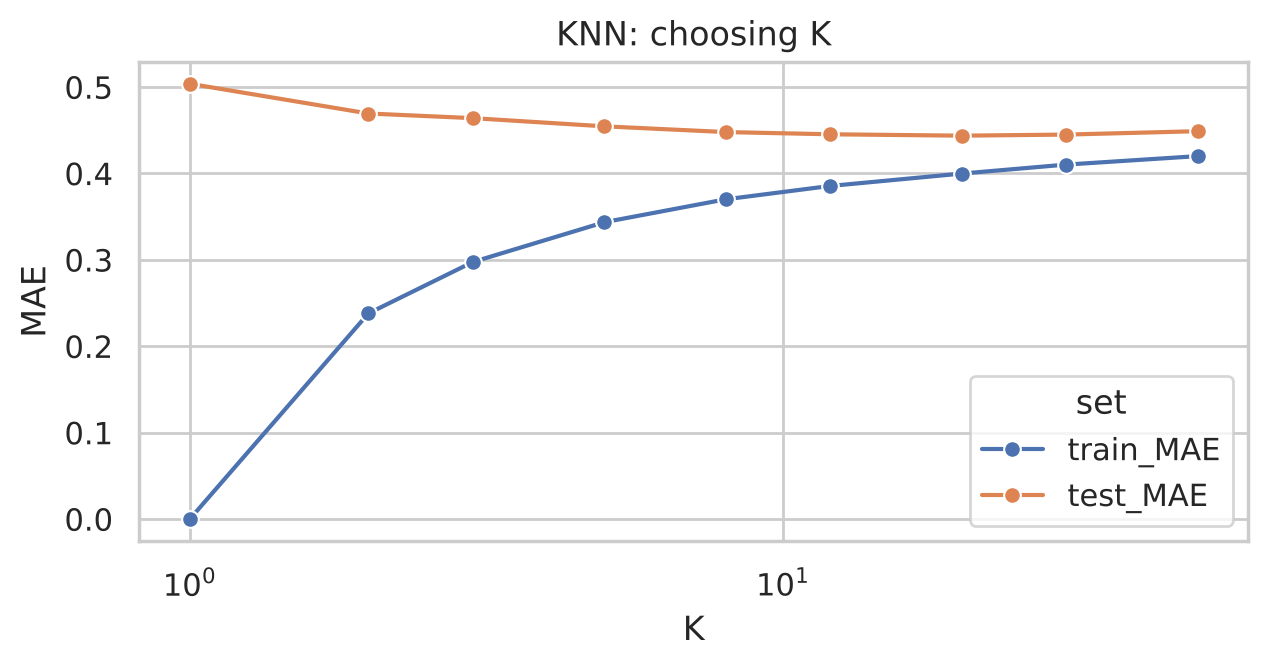

best K on this split: 20


In [9]:
tr, te = splits["random"]; curve = []
for k in [1, 2, 3, 5, 8, 12, 20, 30, 50]:
    m = make_pipeline(StandardScaler(), KNeighborsRegressor(k)).fit(X.loc[tr], y.loc[tr])
    curve.append((k, mean_absolute_error(y.loc[tr], m.predict(X.loc[tr])), mean_absolute_error(y.loc[te], m.predict(X.loc[te]))))
curve = pd.DataFrame(curve, columns=["K", "train_MAE", "test_MAE"])
plt.figure(figsize=(6.5, 3.5)); sns.lineplot(data=curve.melt("K", var_name="set", value_name="MAE"), x="K", y="MAE", hue="set", marker="o"); plt.xscale("log")
plt.title("KNN: choosing K"); plt.tight_layout(); plt.show()
best_k = int(curve.loc[curve.test_MAE.idxmin(), "K"]); print("best K on this split:", best_k)
knn = run(f"KNN (K={best_k})", lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(best_k)))

With K = 1 the *training* error is ~0 (it memorises) but the *test* error is high - that gap is **overfitting**. KNN needs scaled features, because it measures distances.

### 4.5 SVM for regression (SVR) - a flexible "tube" around the data
A Support Vector Machine finds a smooth curve that stays within a margin (`epsilon`) of most points, ignoring small errors. With the **RBF kernel** it can model very curved patterns. `C` sets how strictly it
follows the points. *Real-life example: a road designer draws a smooth road that passes close to survey points without chasing every bump.*
SVMs are **slow on big data**, which is why we sample 20,000 rows.

In [10]:
svr = run("SVM (SVR, RBF kernel)", lambda: make_pipeline(StandardScaler(), SVR(C=3, epsilon=0.05)))
pd.DataFrame(results).round(3).tail(2)

,model,split,train_R2,test_R2,test_MAE,test_RMSE,fit_seconds
12,"SVM (SVR, RBF kernel)",random,0.317,0.239,0.377,0.762,12.722
13,"SVM (SVR, RBF kernel)",unseen routes,0.336,0.166,0.354,0.648,11.855


### 4.6 Decision Tree - a flow-chart of yes/no questions
Learns rules like *"is it 8-9 am? is the stretch near the centre? ..."* until each leaf gives an answer. Easy to read, handles curves and interactions. Too deep a tree **memorises** the data.
*Real-life example: a doctor's triage chart.*

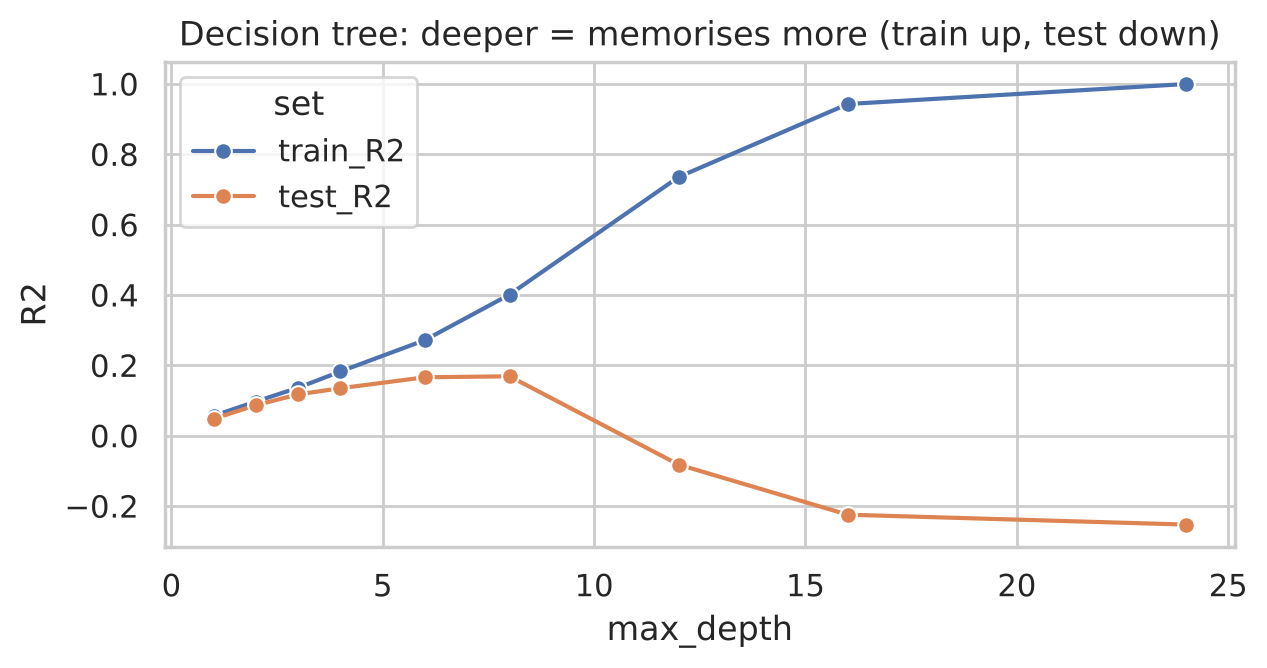

best depth on this split: 8


In [11]:
curve = []
for d in [1, 2, 3, 4, 6, 8, 12, 16, 24]:
    m = DecisionTreeRegressor(max_depth=d, random_state=config.RANDOM_STATE).fit(X.loc[tr], y.loc[tr])
    curve.append((d, r2_score(y.loc[tr], m.predict(X.loc[tr])), r2_score(y.loc[te], m.predict(X.loc[te]))))
curve = pd.DataFrame(curve, columns=["max_depth", "train_R2", "test_R2"])
plt.figure(figsize=(6.5, 3.5)); sns.lineplot(data=curve.melt("max_depth", var_name="set", value_name="R2"), x="max_depth", y="R2", hue="set", marker="o")
plt.title("Decision tree: deeper = memorises more (train up, test down)"); plt.tight_layout(); plt.show()
best_d = int(curve.loc[curve.test_R2.idxmax(), "max_depth"]); print("best depth on this split:", best_d)
tree = run(f"Decision Tree (depth {best_d})", lambda: DecisionTreeRegressor(max_depth=best_d, random_state=config.RANDOM_STATE))

### 4.7 Random Forest - a crowd of trees that vote
Builds many trees, each on a random part of the data, and **averages** them. One tree is jumpy; a hundred averaged trees are steady. Usually a strong all-round model.
*Real-life example: asking 200 people to guess the number of sweets in a jar - the average beats most individuals.*

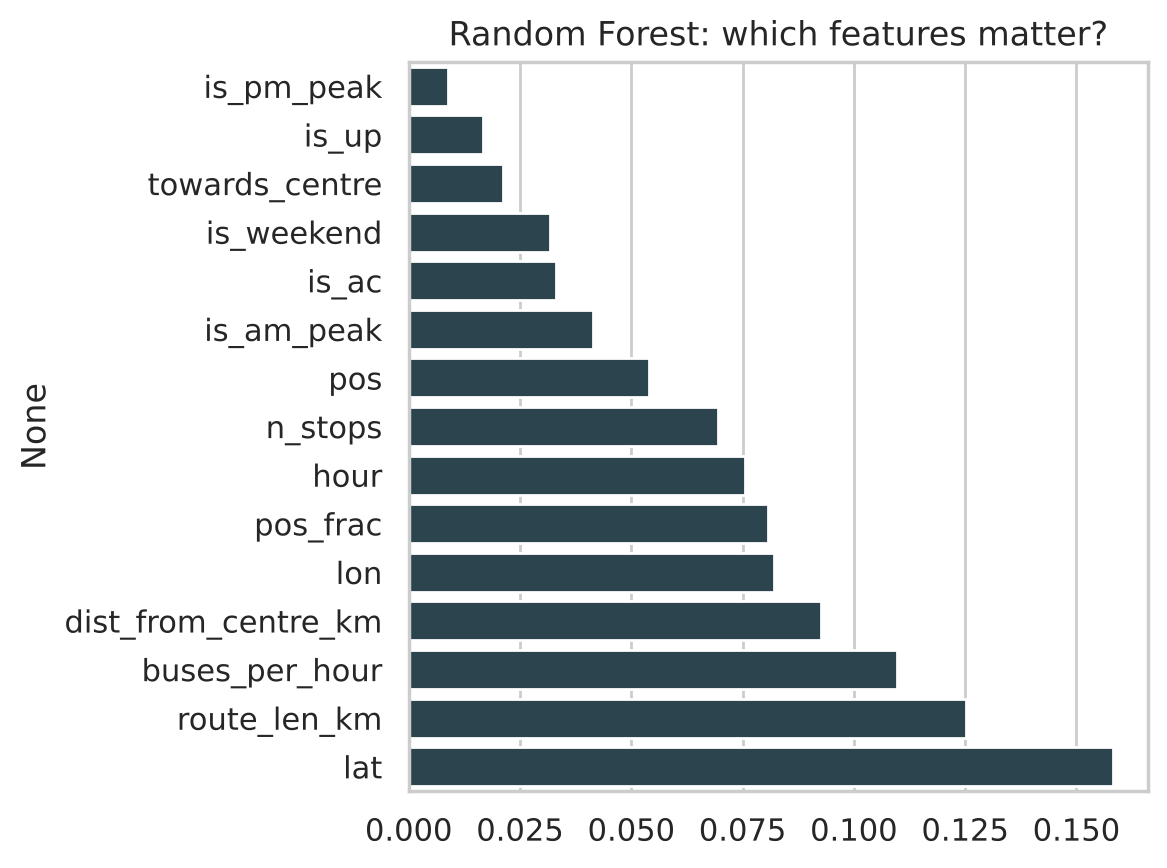

In [12]:
rf = run("Random Forest", lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1, random_state=config.RANDOM_STATE))
imp = pd.Series(rf.feature_importances_, index=mf.FEATURES).sort_values()
plt.figure(figsize=(6, 4.5)); sns.barplot(x=imp.values, y=imp.index, color="#264653"); plt.title("Random Forest: which features matter?"); plt.tight_layout()
plt.savefig(config.FIG / "05_rf_importance.png", dpi=130); plt.show()

### 4.8 Gradient Boosting - trees that fix each other's mistakes
Builds trees **one after another**; each new tree focuses on the errors the previous ones left. Often the most accurate on tables of data like ours.
We use scikit-learn's `HistGradientBoostingRegressor` (fast, no extra install).
*Real-life example: a student who re-does only the questions they got wrong, round after round.*

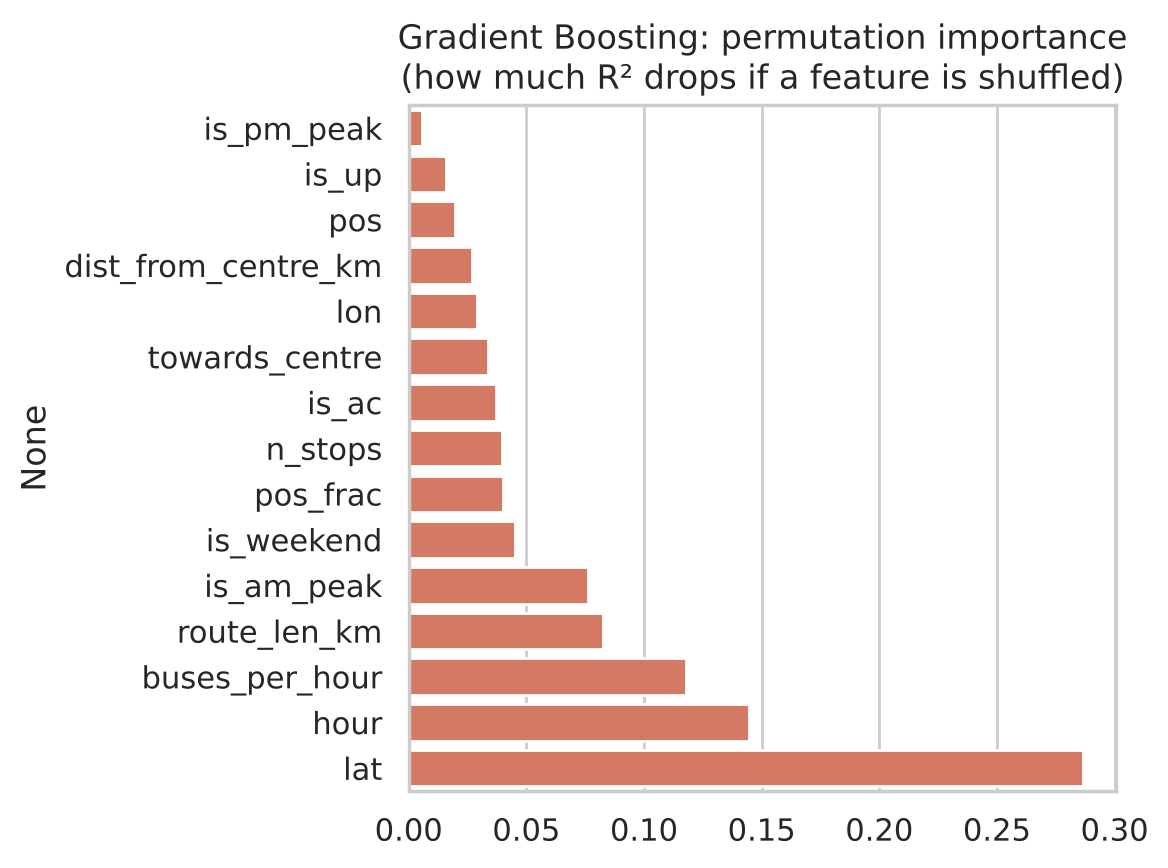

In [13]:
hgb = run("Gradient Boosting", lambda: HistGradientBoostingRegressor(random_state=config.RANDOM_STATE))
pi = permutation_importance(hgb, X.loc[te], y.loc[te], n_repeats=5, random_state=config.RANDOM_STATE, scoring="r2")
pimp = pd.Series(pi.importances_mean, index=mf.FEATURES).sort_values()
plt.figure(figsize=(6, 4.5)); sns.barplot(x=pimp.values, y=pimp.index, color="#e76f51")
plt.title("Gradient Boosting: permutation importance\n(how much R² drops if a feature is shuffled)"); plt.tight_layout(); plt.show()

## 5. Compare all models

split,random,unseen routes
model,,
Gradient Boosting,0.392,0.247
Random Forest,0.358,0.216
"SVM (SVR, RBF kernel)",0.239,0.166
Polynomial (degree 2) + Ridge,0.220,0.171
KNN (K=20),0.200,0.130
Decision Tree (depth 8),0.169,0.091
Ridge,0.115,0.093
Linear Regression,0.115,0.093
Lasso,0.111,0.101


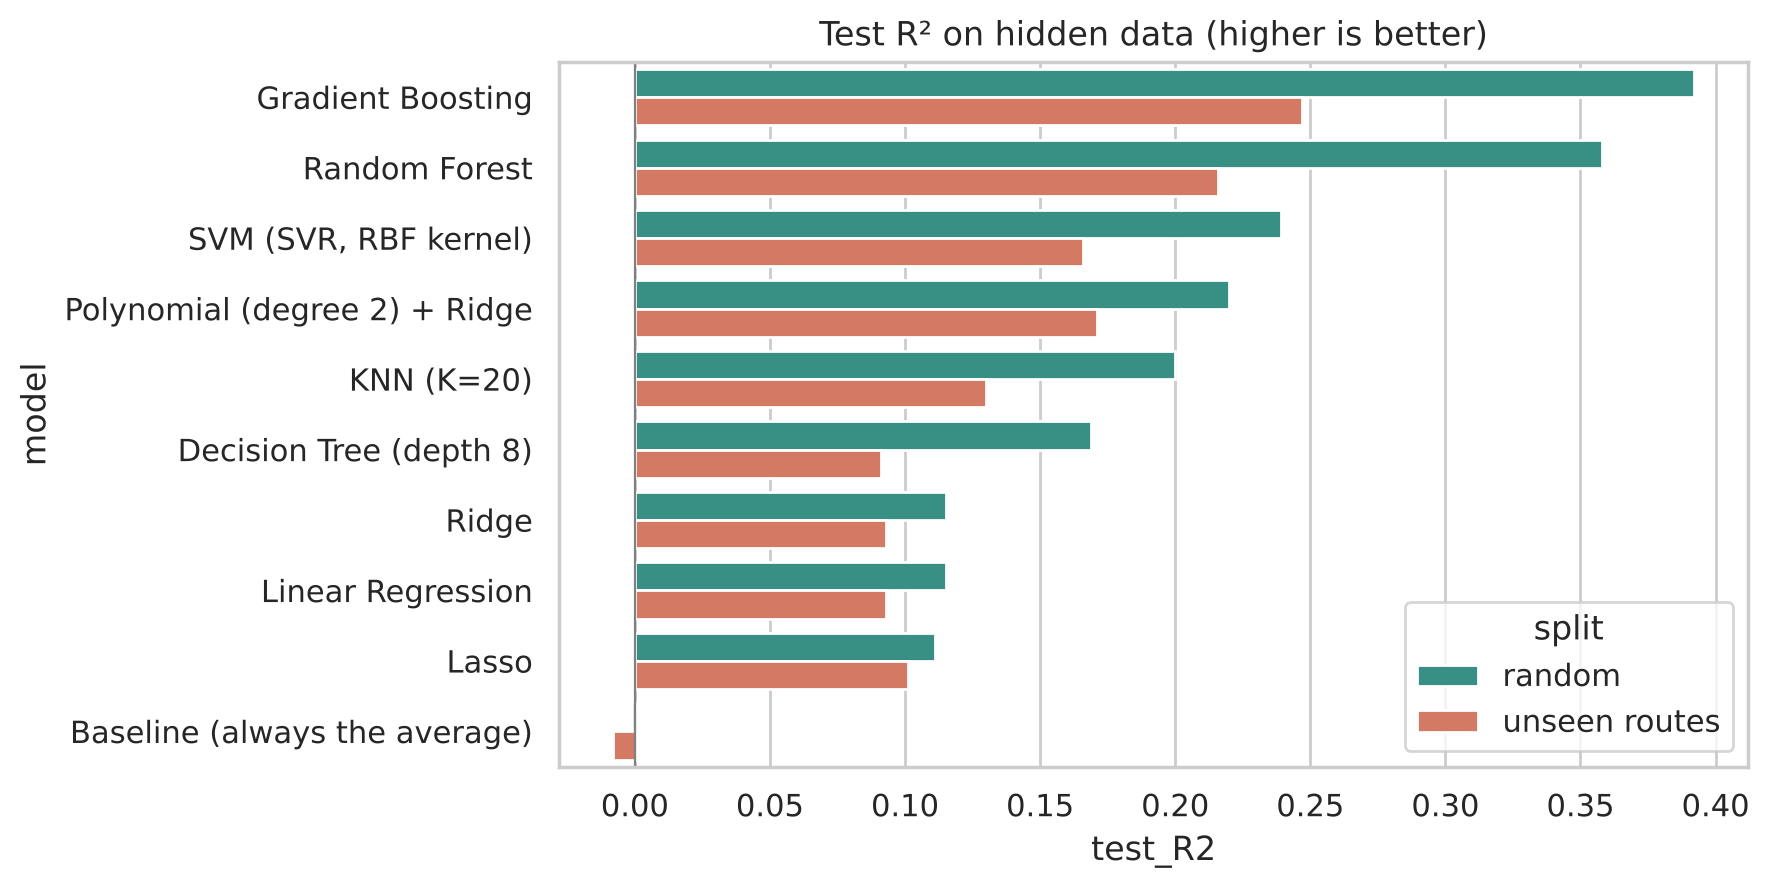

,train_R2,test_R2,test_MAE,test_RMSE,fit_seconds
model,,,,,
Gradient Boosting,0.581,0.392,0.374,0.682,0.220
Random Forest,0.766,0.358,0.385,0.701,10.882
"SVM (SVR, RBF kernel)",0.317,0.239,0.377,0.762,12.722
Polynomial (degree 2) + Ridge,0.242,0.220,0.439,0.772,0.039
KNN (K=20),0.287,0.200,0.444,0.782,0.021
Decision Tree (depth 8),0.401,0.169,0.432,0.797,0.053
Ridge,0.126,0.115,0.471,0.822,0.008
Linear Regression,0.126,0.115,0.471,0.822,0.010
Lasso,0.121,0.111,0.469,0.824,0.008


In [14]:
res = pd.DataFrame(results).round(3)
wide = res.pivot(index="model", columns="split", values="test_R2").sort_values("random", ascending=False)
display(wide)
plt.figure(figsize=(9, 4.6)); sns.barplot(data=res, y="model", x="test_R2", hue="split", order=wide.index, palette=["#2a9d8f", "#e76f51"])
plt.axvline(0, color="grey", lw=0.8); plt.title("Test R² on hidden data (higher is better)"); plt.tight_layout(); plt.savefig(config.FIG / "05_model_comparison.png", dpi=130); plt.show()
res[res.split == "random"][["model", "train_R2", "test_R2", "test_MAE", "test_RMSE", "fit_seconds"]].set_index("model").loc[wide.index]

**What to notice** (the exact numbers are in the table above; read them there)
1. **Straight-line models (Linear, Ridge, Lasso) are the weakest.** Crowding has *peaks and interactions* (hour x position) that one straight line cannot follow. Letting the line bend (Polynomial) improves it clearly.
2. **Ensembles of trees win.** Gradient Boosting is best, then Random Forest. A *single* Decision Tree is weak; KNN and SVM sit in the middle.
3. **Models that can memorise lose accuracy on unseen routes.** Compare a model's *train* R² with its *test* R²: a big gap is overfitting. Simple models barely change between the two splits because they cannot memorise routes in the first place.
   The unseen-routes score is the honest one for "predict a route with no tickets".
4. Even the best R² is **modest**. The target comes from a *sample* of tickets and is noisy, so we are not claiming precise prediction - the point is the *ranking of models* and what drives crowding.
5. **One split can mislead.** Section 6 (cross-validation by route) usually gives a lower, more honest score than a single lucky split - this is why we average over several splits.

## 6. Cross-validation: a more trustworthy score
One split can be lucky. **K-fold cross-validation** repeats the experiment 5 times with different hidden parts and reports the average and the spread.
We use `GroupKFold` so whole routes stay together (no peeking).

In [15]:
gkf = GroupKFold(n_splits=5)
cv_models = {"Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
             "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(best_k)),
             "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, n_jobs=-1, random_state=config.RANDOM_STATE),
             "Gradient Boosting": HistGradientBoostingRegressor(random_state=config.RANDOM_STATE)}
cv_rows = []
for name, m in cv_models.items():
    sc = cross_val_score(m, X, y, cv=gkf, groups=groups, scoring="r2")
    cv_rows.append(dict(model=name, mean_R2=sc.mean(), std_R2=sc.std(), folds=np.round(sc, 2).tolist()))
cv = pd.DataFrame(cv_rows).round(3); cv

,model,mean_R2,std_R2,folds
0,Linear Regression,0.113,0.031,"[0.1, 0.17, 0.11, 0.08, 0.09]"
1,KNN,0.129,0.014,"[0.15, 0.14, 0.13, 0.11, 0.12]"
2,Random Forest,0.216,0.016,"[0.23, 0.23, 0.19, 0.22, 0.2]"
3,Gradient Boosting,0.264,0.033,"[0.28, 0.32, 0.24, 0.25, 0.24]"


## 7. GridSearchCV: let the computer try settings
Models have **settings** (called *hyper-parameters*): learning rate, tree size ... `GridSearchCV` tries every combination with cross-validation and keeps the best. It only ever looks at the *training* routes.

In [16]:
grid = GridSearchCV(HistGradientBoostingRegressor(random_state=config.RANDOM_STATE),
                    param_grid={"learning_rate": [0.05, 0.1], "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [20, 50]},
                    cv=GroupKFold(n_splits=3), scoring="r2", n_jobs=-1)
tr, te = splits["unseen routes"]
grid.fit(X.loc[tr], y.loc[tr], groups=groups.loc[tr])
print("Best settings:", grid.best_params_)
print("Cross-validated R² on training routes: %.3f" % grid.best_score_)
print("R² on the HIDDEN routes: %.3f  (default settings gave %.3f)" % (r2_score(y.loc[te], grid.predict(X.loc[te])),
      res[(res.model == "Gradient Boosting") & (res.split == "unseen routes")].test_R2.iloc[0]))

Best settings: {'learning_rate': 0.1, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}
Cross-validated R² on training routes: 0.276
R² on the HIDDEN routes: 0.234  (default settings gave 0.247)


**Honest note:** tuning does not always beat the defaults on hidden routes - it is only as good as the cross-validation behind it, and this data is noisy. Compare the two numbers printed above.

## 8. One more trick: predict the *log* of the target
The target is skewed (a few huge values). Predicting `log(1 + index)` and converting back often helps, because big values no longer dominate the error.

In [17]:
logm = run("Gradient Boosting on log(target)", lambda: TransformedTargetRegressor(HistGradientBoostingRegressor(random_state=config.RANDOM_STATE), func=np.log1p, inverse_func=np.expm1))
out = pd.DataFrame(results).round(3)
out[out.model.str.startswith("Gradient")][["model", "split", "test_R2", "test_MAE"]]

,model,split,test_R2,test_MAE
18,Gradient Boosting,random,0.392,0.374
19,Gradient Boosting,unseen routes,0.247,0.355
20,Gradient Boosting on log(target),random,0.373,0.359
21,Gradient Boosting on log(target),unseen routes,0.248,0.337


Best model on unseen routes: Gradient Boosting


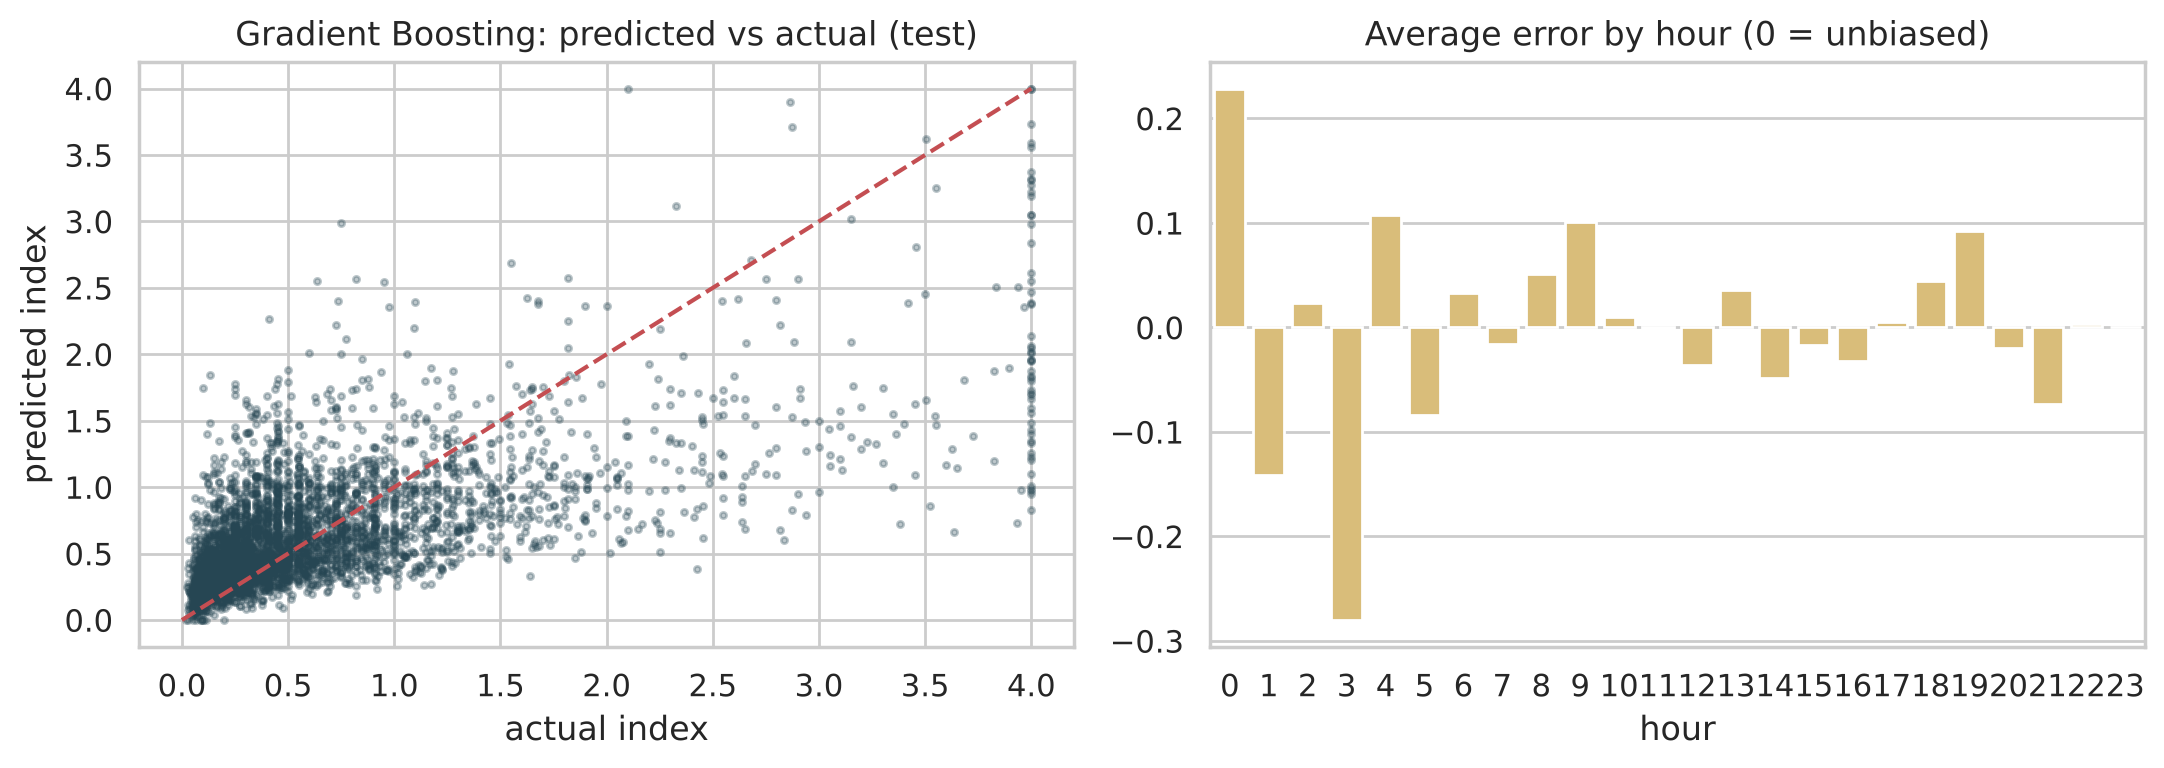

In [18]:
best_name = res[res.split == "unseen routes"].sort_values("test_R2", ascending=False).iloc[0].model
print("Best model on unseen routes:", best_name)
m = fitted[best_name]; tr, te = splits["random"]; pred = m.predict(X.loc[te])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y.loc[te].clip(upper=4), np.clip(pred, 0, 4), s=5, alpha=0.3, color="#264653"); ax[0].plot([0, 4], [0, 4], "r--"); ax[0].set_xlabel("actual index"); ax[0].set_ylabel("predicted index"); ax[0].set_title(f"{best_name}: predicted vs actual (test)")
resid = (y.loc[te] - pred).groupby(S.loc[te, "hour"]).mean(); sns.barplot(x=resid.index, y=resid.values, ax=ax[1], color="#e9c46a"); ax[1].set_title("Average error by hour (0 = unbiased)")
plt.tight_layout(); plt.savefig(config.FIG / "05_best_model.png", dpi=130); plt.show()

Points along the red line would be perfect predictions. The model is good at the *general level*, weaker at the **extremes** (the very busiest cells), which is typical for noisy targets.

## 9. Save results and the best model (the app has an ML page that uses it)

In [19]:
db.save_table(res, "ml_regression_results", engine)
db.save_table(cv.assign(folds=cv.folds.astype(str)), "ml_regression_cv", engine)
final = HistGradientBoostingRegressor(random_state=config.RANDOM_STATE, **{k: v for k, v in grid.best_params_.items()}).fit(X, y)
(config.OUT / "models").mkdir(exist_ok=True)
joblib.dump({"model": final, "features": mf.FEATURES, "ref_idx": np.quantile(ds.idx, np.linspace(0, 1, 401))}, config.OUT / "models" / "best_regressor.joblib")
import json
(config.OUT / "05_regression_results.json").write_text(json.dumps({"best_on_unseen_routes": best_name, "table": res.to_dict("records"),
                                                                   "cv": cv.drop(columns="folds").to_dict("records"), "grid_best_params": grid.best_params_}, indent=2, default=float))
print("saved: database table ml_regression_results, outputs/models/best_regressor.joblib")

saved: database table ml_regression_results, outputs/models/best_regressor.joblib


## Summary
| Lesson | Where you saw it |
|---|---|
| Always evaluate on **hidden** data | Section 3 |
| A random split can flatter a model; **group** splits are more honest | Sections 3, 5 |
| **Overfitting**: memorising training data | KNN with K=1, deep trees |
| Straight-line models miss curves; trees and boosting capture them | Section 5 |
| **Regularisation** (Ridge/Lasso) and **feature scaling** | 4.2, 4.1 |
| **Cross-validation** and **GridSearchCV** for trustworthy scores and settings | Sections 6-7 |

**Next:** `06_ml_classification.ipynb` - predict the *level* (Quiet / Moderate / Busy) instead of a number.